Part 1.1
# Libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

df = pd.read_excel(
    "ebayAuctions.xlsx",
    sheet_name="eBay auctions"
)

df.head()

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?,Unnamed: 8
0,Music/Movie/Game,US,37727.0,7.0,Mon,0.01,0.01,0.0,NaN
1,Music/Movie/Game,US,37727.0,7.0,Mon,4.26,0.01,1.0,NaN
2,SportingGoods,US,34343.0,1.0,Fri,0.11,0.01,1.0,NaN
3,SportingGoods,US,27132.0,5.0,Mon,17.01,0.99,1.0,NaN
4,SportingGoods,US,27132.0,5.0,Mon,19.02,0.99,1.0,NaN


In [2]:
print("Dataset shape:", df.shape)

df.info()
display(df.describe(include="all"))

Dataset shape: (1975, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1975 entries, 0 to 1974
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   str    
 1   Currency      1972 non-null   str    
 2   sellerRating  1972 non-null   float64
 3   Duration      1972 non-null   float64
 4   endDay        1972 non-null   str    
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1974 non-null   float64
 8   Unnamed: 8    1 non-null      float64
dtypes: float64(6), str(3)
memory usage: 139.0 KB


,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?,Unnamed: 8
count,1972,1972,1972.000000,1972.000000,1972,1972.000000,1972.000000,1974.000000,1.000000
unique,18,3,NaN,NaN,7,NaN,NaN,NaN,NaN
top,Music/Movie/Game,US,NaN,NaN,Mon,NaN,NaN,NaN,NaN
freq,403,1292,NaN,NaN,548,NaN,NaN,NaN,NaN
mean,NaN,NaN,3560.238337,6.486308,NaN,36.449087,12.926268,1.905775,0.548535
std,NaN,NaN,5973.011033,2.052906,NaN,89.493858,38.856149,44.670344,NaN
min,NaN,NaN,0.000000,1.000000,NaN,0.010000,0.010000,0.000000,0.548535
25%,NaN,NaN,595.000000,5.000000,NaN,4.907500,1.230000,0.000000,0.548535
50%,NaN,NaN,1853.000000,7.000000,NaN,9.995000,4.500000,1.000000,0.548535
75%,NaN,NaN,3380.000000,7.000000,NaN,28.000000,9.990000,1.000000,0.548535


In [3]:
# Remove irrelevant column
df = df.drop("Unnamed: 8", axis=1)

# Remove extra rows
df = df[df["Competitive?"].isin([0, 1])]

# Reset index
df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (1972, 8)


In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)":
        df.isnull().mean() * 100
})

missing_summary

,Missing Count,Missing Percentage (%)
Category,0,0.0
Currency,0,0.0
sellerRating,0,0.0
Duration,0,0.0
endDay,0,0.0
ClosePrice,0,0.0
OpenPrice,0,0.0
Competitive?,0,0.0


In [5]:
df.duplicated().sum()
df[df.duplicated()]

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?
54,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
55,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
56,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
72,Pottery/Glass,GBP,5292.0,7.0,Thu,1.78,1.78,0.0
79,Computer,EUR,3375.0,10.0,Thu,1.23,1.23,0.0
...,...,...,...,...,...,...,...,...
1925,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1926,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1927,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1928,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1972 entries, 0 to 1971
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   str    
 1   Currency      1972 non-null   str    
 2   sellerRating  1972 non-null   float64
 3   Duration      1972 non-null   float64
 4   endDay        1972 non-null   str    
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1972 non-null   float64
dtypes: float64(5), str(3)
memory usage: 123.4 KB


In [7]:
df.describe()

,sellerRating,Duration,ClosePrice,OpenPrice,Competitive?
count,1972.000000,1972.000000,1972.000000,1972.000000,1972.000000
mean,3560.238337,6.486308,36.449087,12.926268,0.540568
std,5973.011033,2.052906,89.493858,38.856149,0.498478
min,0.000000,1.000000,0.010000,0.010000,0.000000
25%,595.000000,5.000000,4.907500,1.230000,0.000000
50%,1853.000000,7.000000,9.995000,4.500000,1.000000
75%,3380.000000,7.000000,28.000000,9.990000,1.000000
max,37727.000000,10.000000,999.000000,999.000000,1.000000


In [8]:
for col in ["Category", "Currency", "Duration",
            "endDay", "Competitive?"]:
    print(col, df[col].unique())

print("Negative seller ratings:",
      (df["sellerRating"] < 0).sum())

print("Non-positive opening prices:",
      (df["OpenPrice"] <= 0).sum())

print("Non-positive closing prices:",
      (df["ClosePrice"] <= 0).sum())

print("Closing price below opening price:",
      (df["ClosePrice"] < df["OpenPrice"]).sum())

Category <StringArray>
[    'Music/Movie/Game',        'SportingGoods',  'Business/Industrial',
           'Automotive',         'Collectibles',          'Home/Garden',
              'Jewelry',          'Electronics',         'Coins/Stamps',
        'Pottery/Glass',             'Computer',         'Toys/Hobbies',
 'Clothing/Accessories',    'Antique/Art/Craft',                'Books',
        'Health/Beauty',       'EverythingElse',          'Photography']
Length: 18, dtype: str
Currency <StringArray>
['US', 'EUR', 'GBP']
Length: 3, dtype: str
Duration [ 7.  1.  5.  3. 10.]
endDay <StringArray>
['Mon', 'Fri', 'Sun', 'Tue', 'Wed', 'Thu', 'Sat']
Length: 7, dtype: str
Competitive? [0. 1.]
Negative seller ratings: 0
Non-positive opening prices: 0
Non-positive closing prices: 0
Closing price below opening price: 0


Part 1.2
# Data Processing and EDA

In [9]:
categorical_cols = [
    "Category", "Currency", "Duration", "endDay"
]

numerical_cols = [
    "sellerRating", "OpenPrice", "ClosePrice"
]

for col in categorical_cols:
    df[col] = df[col].astype("category")

df["Competitive?"] = df["Competitive?"].astype(int)

In [10]:
target = "Competitive?"

# Model 1: All available predictors
all_predictors = [
    "Category",
    "Currency",
    "sellerRating",
    "Duration",
    "endDay",
    "ClosePrice",
    "OpenPrice"
]

# Model 2 and k-NN: Predictors available before auction
practical_predictors = [
    col for col in all_predictors
    if col != "ClosePrice"
]

In [11]:
train_df, test_df = train_test_split(
    df,
    test_size=0.4,
    random_state=5,
    stratify=df[target]
)

y_train = train_df[target].copy()
y_test = test_df[target].copy()

print("Training set:", train_df.shape)
print("Test set:", test_df.shape)

Training set: (1183, 8)
Test set: (789, 8)


In [12]:
distribution = pd.DataFrame({
    "Full Dataset":
        df[target].value_counts(normalize=True),

    "Training Set":
        y_train.value_counts(normalize=True),

    "Test Set":
        y_test.value_counts(normalize=True)
}) * 100

display(distribution.round(2))

,Full Dataset,Training Set,Test Set
Competitive?,,,
1,54.06,54.02,54.12
0,45.94,45.98,45.88


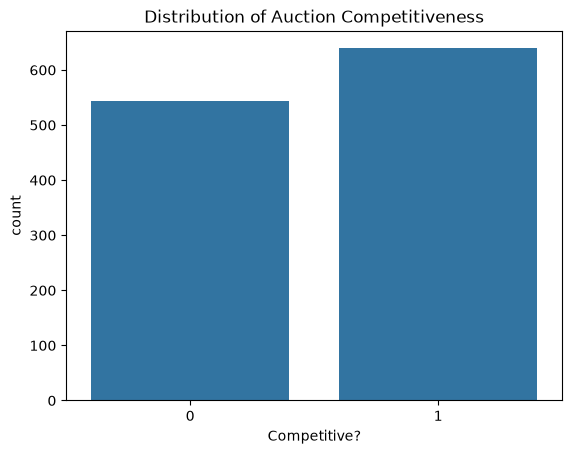

In [13]:
sns.countplot(data=train_df, x="Competitive?")
plt.title("Distribution of Auction Competitiveness")
plt.show()

In [14]:
train_df["Competitive?"].value_counts(normalize=True)

Competitive?
1    0.540152
0    0.459848
Name: proportion, dtype: float64

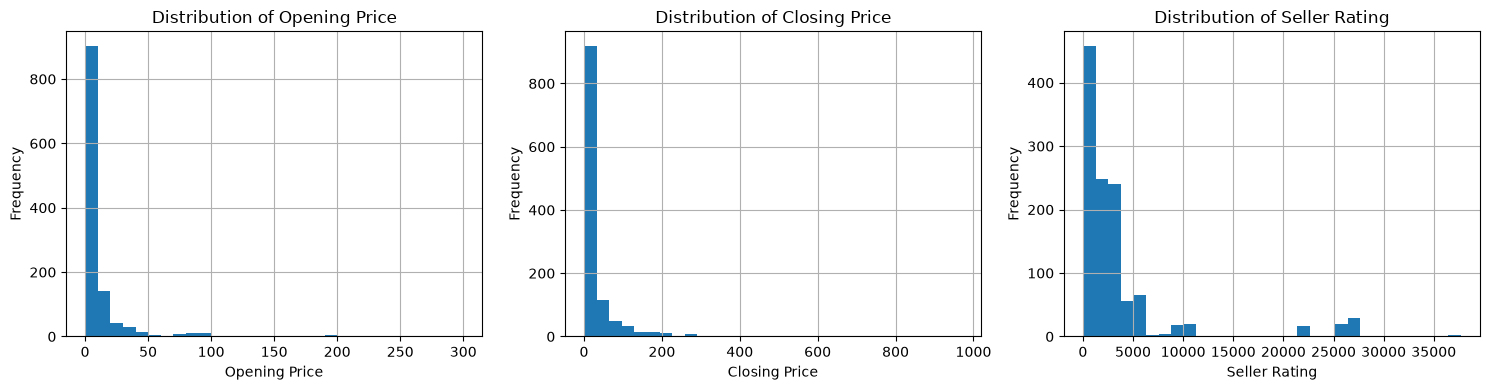

In [15]:
plt.figure(figsize=(15, 4))

# Opening Price
plt.subplot(1, 3, 1)
train_df["OpenPrice"].hist(bins=30)
plt.title("Distribution of Opening Price")
plt.xlabel("Opening Price")
plt.ylabel("Frequency")

# Closing Price
plt.subplot(1, 3, 2)
train_df["ClosePrice"].hist(bins=30)
plt.title("Distribution of Closing Price")
plt.xlabel("Closing Price")
plt.ylabel("Frequency")

# Seller Rating
plt.subplot(1, 3, 3)
train_df["sellerRating"].hist(bins=30)
plt.title("Distribution of Seller Rating")
plt.xlabel("Seller Rating")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

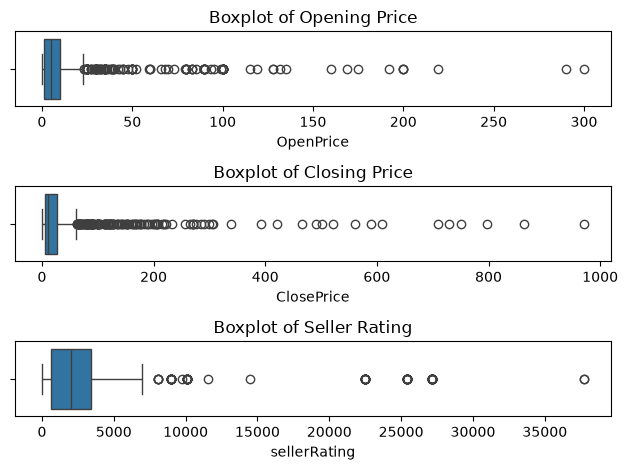

In [16]:
# Opening Price
plt.subplot(3, 1, 1)
sns.boxplot(data=train_df, x="OpenPrice")
plt.title("Boxplot of Opening Price")

# Closing Price
plt.subplot(3, 1, 2)
sns.boxplot(data=train_df, x="ClosePrice")
plt.title("Boxplot of Closing Price")

# Seller Rating
plt.subplot(3, 1, 3)
sns.boxplot(data=train_df, x="sellerRating")
plt.title("Boxplot of Seller Rating")

plt.tight_layout()
plt.show()

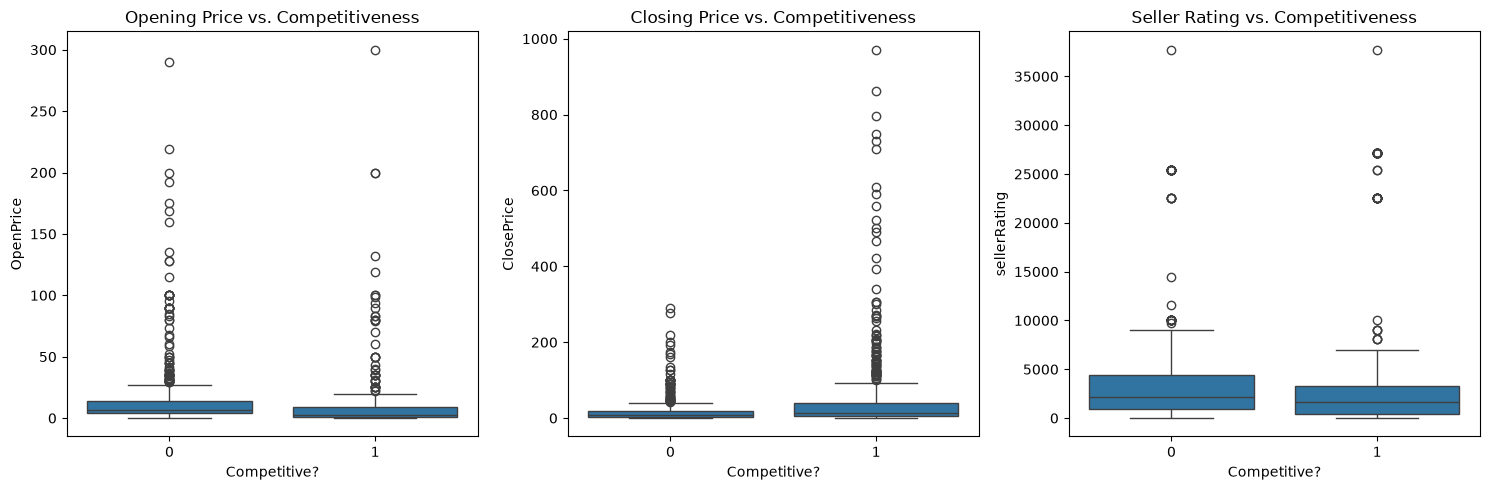

In [17]:
plt.figure(figsize=(15, 5))

# Opening Price vs. Target
plt.subplot(1, 3, 1)
sns.boxplot(data=train_df, x="Competitive?", y="OpenPrice")
plt.title("Opening Price vs. Competitiveness")

# Closing Price vs. Target
plt.subplot(1, 3, 2)
sns.boxplot(data=train_df, x="Competitive?", y="ClosePrice")
plt.title("Closing Price vs. Competitiveness")

# Seller Rating vs. Target
plt.subplot(1, 3, 3)
sns.boxplot(data=train_df, x="Competitive?", y="sellerRating")
plt.title("Seller Rating vs. Competitiveness")

plt.tight_layout()
plt.show()

In [18]:
train_df.groupby("Competitive?")[numerical_cols].median()

,sellerRating,OpenPrice,ClosePrice
Competitive?,,,
0,2204.5,6.99,7.99
1,1647.0,2.45,14.13


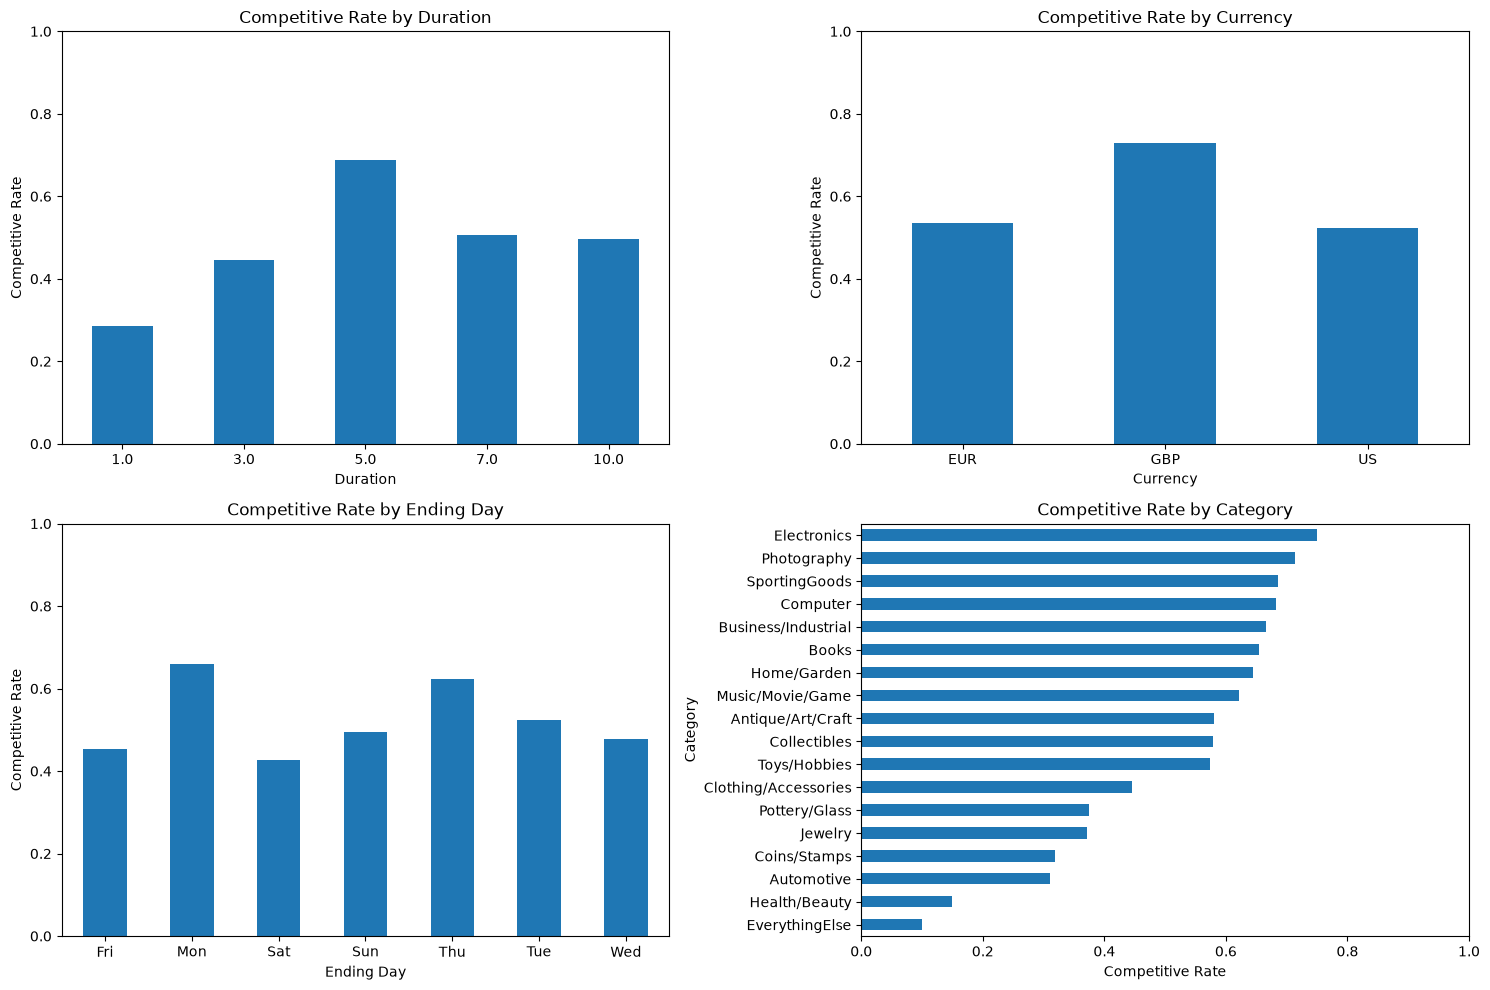

In [19]:
plt.figure(figsize=(15, 10))

# Duration
plt.subplot(2, 2, 1)
train_df.groupby("Duration")["Competitive?"].mean().plot(kind="bar")
plt.title("Competitive Rate by Duration")
plt.ylabel("Competitive Rate")
plt.xlabel("Duration")
plt.ylim(0, 1)
plt.xticks(rotation=0)

# Currency
plt.subplot(2, 2, 2)
train_df.groupby("Currency")["Competitive?"].mean().plot(kind="bar")
plt.title("Competitive Rate by Currency")
plt.ylabel("Competitive Rate")
plt.xlabel("Currency")
plt.ylim(0, 1)
plt.xticks(rotation=0)

# Ending Day
plt.subplot(2, 2, 3)
train_df.groupby("endDay")["Competitive?"].mean().plot(kind="bar")
plt.title("Competitive Rate by Ending Day")
plt.ylabel("Competitive Rate")
plt.xlabel("Ending Day")
plt.ylim(0, 1)
plt.xticks(rotation=0)

# Category
plt.subplot(2, 2, 4)
train_df.groupby("Category")["Competitive?"].mean().sort_values().plot(kind="barh")
plt.title("Competitive Rate by Category")
plt.xlabel("Competitive Rate")
plt.ylabel("Category")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [20]:
print(train_df.groupby("Duration")["Competitive?"].agg(["count", "mean"]))
print(train_df.groupby("Currency")["Competitive?"].agg(["count", "mean"]))
print(train_df.groupby("endDay")["Competitive?"].agg(["count", "mean"]))
print(train_df.groupby("Category")["Competitive?"].agg(["count", "mean"]))

          count      mean
Duration                 
1.0           7  0.285714
3.0         135  0.444444
5.0         283  0.689046
7.0         585  0.505983
10.0        173  0.497110
          count      mean
Currency                 
EUR         303  0.534653
GBP          85  0.729412
US          795  0.522013
        count      mean
endDay                 
Fri       170  0.452941
Mon       347  0.659942
Sat       202  0.425743
Sun       198  0.494949
Thu       117  0.623932
Tue       105  0.523810
Wed        44  0.477273
                      count      mean
Category                             
Antique/Art/Craft       112  0.580357
Automotive              113  0.309735
Books                    26  0.653846
Business/Industrial      12  0.666667
Clothing/Accessories     74  0.445946
Coins/Stamps             22  0.318182
Collectibles            128  0.578125
Computer                 22  0.681818
Electronics              36  0.750000
EverythingElse           10  0.100000
Health/Beauty   

In [21]:
numerical_cols = ["OpenPrice", "ClosePrice", "sellerRating"]

corr = train_df[numerical_cols + [target]].corr()

corr

,OpenPrice,ClosePrice,sellerRating,Competitive?
OpenPrice,1.000000,0.354618,-0.043711,-0.155456
ClosePrice,0.354618,1.000000,0.013774,0.183881
sellerRating,-0.043711,0.013774,1.000000,-0.026347
Competitive?,-0.155456,0.183881,-0.026347,1.000000


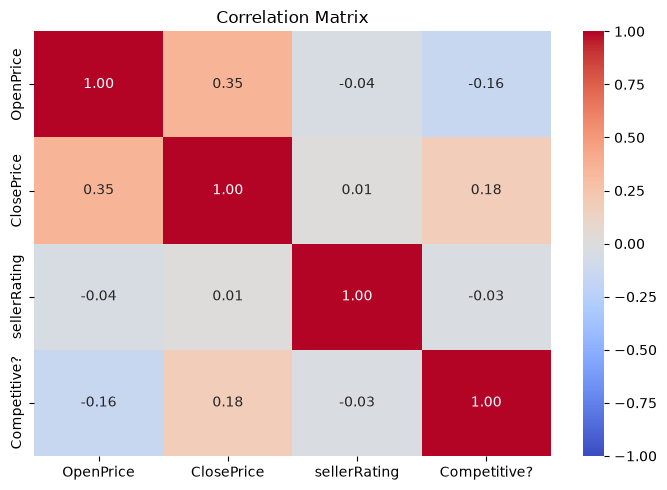

In [22]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

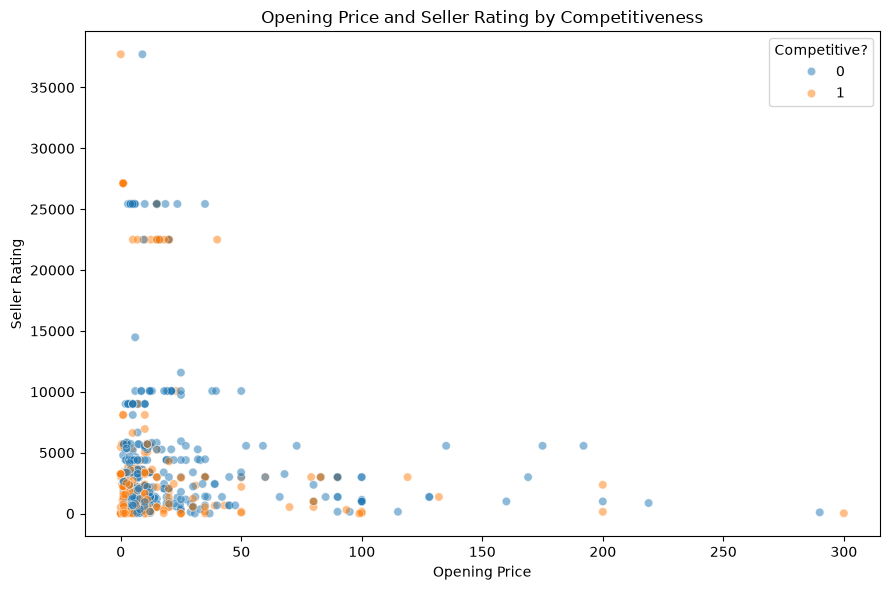

In [23]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=train_df,
    x="OpenPrice",
    y="sellerRating",
    hue="Competitive?",
    alpha=0.5
)

plt.title("Opening Price and Seller Rating by Competitiveness")
plt.xlabel("Opening Price")
plt.ylabel("Seller Rating")
plt.tight_layout()
plt.show()

Part 1.3
# Encoding and scaling

In [24]:
categorical_cols = [
    "Category",
    "Currency",
    "Duration",
    "endDay"
]

train_encoded = pd.get_dummies(
    train_df,
    columns=categorical_cols,
    dtype=int
)

train_encoded.head()

,sellerRating,ClosePrice,OpenPrice,Competitive?,Category_Antique/Art/Craft,Category_Automotive,Category_Books,Category_Business/Industrial,Category_Clothing/Accessories,Category_Coins/Stamps,...,Duration_5.0,Duration_7.0,Duration_10.0,endDay_Fri,endDay_Mon,endDay_Sat,endDay_Sun,endDay_Thu,endDay_Tue,endDay_Wed
891,215.0,1.77,1.77,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
788,632.0,8.91,8.91,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
1944,1364.0,135.00,132.00,1,0,1,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
945,1634.0,7.37,7.37,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
338,1179.0,49.79,1.23,1,0,0,0,0,0,0,...,0,1,0,0,0,0,1,0,0,0


In [25]:
test_encoded = pd.get_dummies(
    test_df,
    columns=categorical_cols,
    dtype=int
)

test_encoded.head()

,sellerRating,ClosePrice,OpenPrice,Competitive?,Category_Antique/Art/Craft,Category_Automotive,Category_Books,Category_Business/Industrial,Category_Clothing/Accessories,Category_Coins/Stamps,...,Duration_5.0,Duration_7.0,Duration_10.0,endDay_Fri,endDay_Mon,endDay_Sat,endDay_Sun,endDay_Thu,endDay_Tue,endDay_Wed
1359,3385.0,12.50,8.99,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
1563,957.0,15.99,15.99,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0
1379,41.0,3.69,1.23,1,0,0,0,0,1,0,...,0,0,1,0,0,0,1,0,0,0
65,5701.0,15.37,1.23,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
695,3385.0,5.50,2.99,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0


In [26]:
# Ensure that the test set has the same columns as the training set
test_encoded = test_encoded.reindex(
    columns=train_encoded.columns,
    fill_value=0
)

print("Encoded training set:", train_encoded.shape)
print("Encoded testing set:", test_encoded.shape)
train_encoded.columns

Encoded training set: (1183, 37)
Encoded testing set: (789, 37)


Index(['sellerRating', 'ClosePrice', 'OpenPrice', 'Competitive?',
       'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books',
       'Category_Business/Industrial', 'Category_Clothing/Accessories',
       'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer',
       'Category_Electronics', 'Category_EverythingElse',
       'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry',
       'Category_Music/Movie/Game', 'Category_Photography',
       'Category_Pottery/Glass', 'Category_SportingGoods',
       'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US',
       'Duration_1.0', 'Duration_3.0', 'Duration_5.0', 'Duration_7.0',
       'Duration_10.0', 'endDay_Fri', 'endDay_Mon', 'endDay_Sat', 'endDay_Sun',
       'endDay_Thu', 'endDay_Tue', 'endDay_Wed'],
      dtype='str')

Part 1.4
# Prepare Data for Classification Trees

In [27]:
# Initial Classification Model: All available predictors

X_train = train_encoded.drop("Competitive?", axis=1)
y_train = train_encoded["Competitive?"]

X_test = test_encoded.drop("Competitive?", axis=1)
y_test = test_encoded["Competitive?"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1183, 36)
X_test: (789, 36)
y_train: (1183,)
y_test: (789,)


In [28]:
# Practical Classification Model: Predictors available before auction
X_train_practical = X_train.drop("ClosePrice", axis=1)

X_test_practical = X_test.drop("ClosePrice", axis=1)

print("Practical training set:", X_train_practical.shape)
print("Practical testing set:", X_test_practical.shape)

Practical training set: (1183, 35)
Practical testing set: (789, 35)


# Part 2: Classification Tree Using All Predictors

## 2.1 Model Training

In [29]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

tree_all = DecisionTreeClassifier(
    criterion="gini",
    min_samples_leaf=50,
    random_state=5
)

tree_all.fit(X_train, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",5
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [30]:
print("Tree depth:", tree_all.get_depth())
print("Number of terminal nodes:", tree_all.get_n_leaves())
print("Training accuracy:", tree_all.score(X_train, y_train))
print("Test accuracy:", tree_all.score(X_test, y_test))

Tree depth: 7
Number of terminal nodes: 16
Training accuracy: 0.8250211327134404
Test accuracy: 0.8326996197718631


## 2.2 Decision Tree Visualization

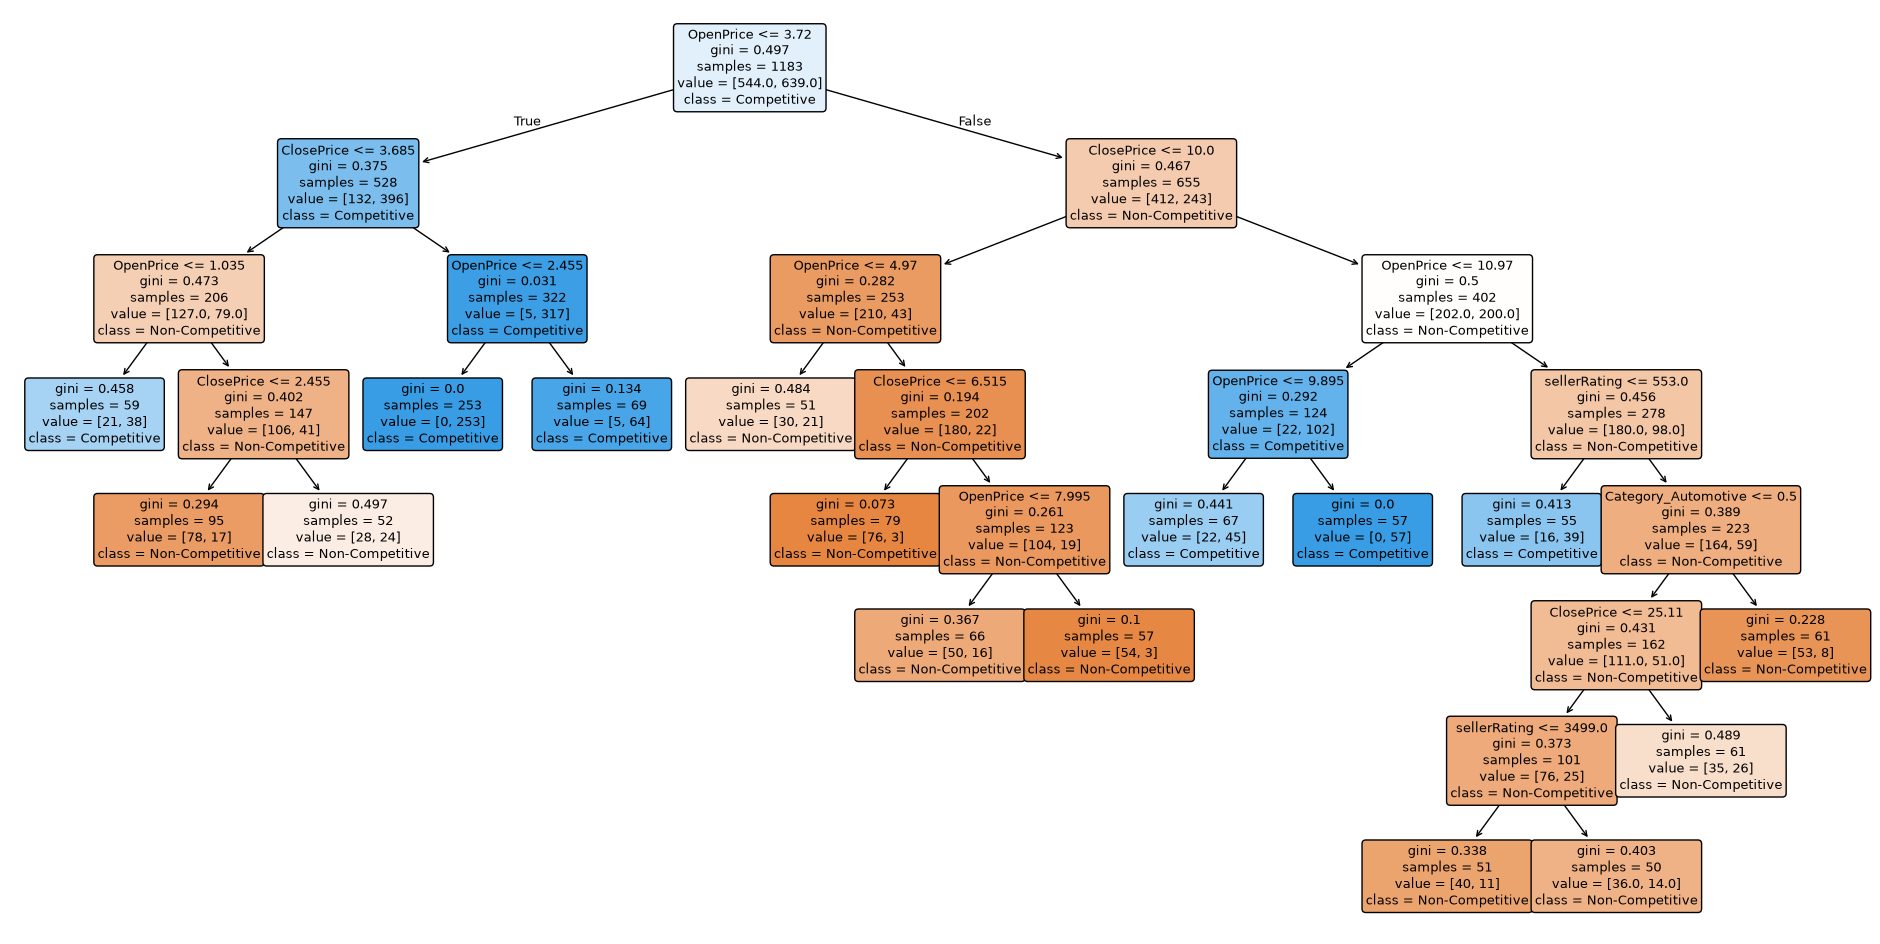

In [31]:
plt.figure(figsize=(24, 12))

plot_tree(
    tree_all,
    feature_names=X_train.columns,
    class_names=["Non-Competitive", "Competitive"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

## 2.3 Decision Rules

In [32]:
rules_all = export_text(
    tree_all,
    feature_names=list(X_train.columns)
)

print(rules_all)

|--- OpenPrice <= 3.72
|   |--- ClosePrice <= 3.69
|   |   |--- OpenPrice <= 1.04
|   |   |   |--- class: 1
|   |   |--- OpenPrice >  1.04
|   |   |   |--- ClosePrice <= 2.46
|   |   |   |   |--- class: 0
|   |   |   |--- ClosePrice >  2.46
|   |   |   |   |--- class: 0
|   |--- ClosePrice >  3.69
|   |   |--- OpenPrice <= 2.46
|   |   |   |--- class: 1
|   |   |--- OpenPrice >  2.46
|   |   |   |--- class: 1
|--- OpenPrice >  3.72
|   |--- ClosePrice <= 10.00
|   |   |--- OpenPrice <= 4.97
|   |   |   |--- class: 0
|   |   |--- OpenPrice >  4.97
|   |   |   |--- ClosePrice <= 6.52
|   |   |   |   |--- class: 0
|   |   |   |--- ClosePrice >  6.52
|   |   |   |   |--- OpenPrice <= 7.99
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- OpenPrice >  7.99
|   |   |   |   |   |--- class: 0
|   |--- ClosePrice >  10.00
|   |   |--- OpenPrice <= 10.97
|   |   |   |--- OpenPrice <= 9.89
|   |   |   |   |--- class: 1
|   |   |   |--- OpenPrice >  9.89
|   |   |   |   |--- class: 1
|   |   

## 2.4 Feature Importance

In [33]:
importance_all = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tree_all.feature_importances_
}).sort_values("Importance", ascending=False)

importance_all

,Feature,Importance
2,OpenPrice,0.493732
1,ClosePrice,0.438348
0,sellerRating,0.058079
4,Category_Automotive,0.009841
34,endDay_Tue,0.000000
33,endDay_Thu,0.000000
32,endDay_Sun,0.000000
31,endDay_Sat,0.000000
30,endDay_Mon,0.000000
20,Category_Toys/Hobbies,0.000000


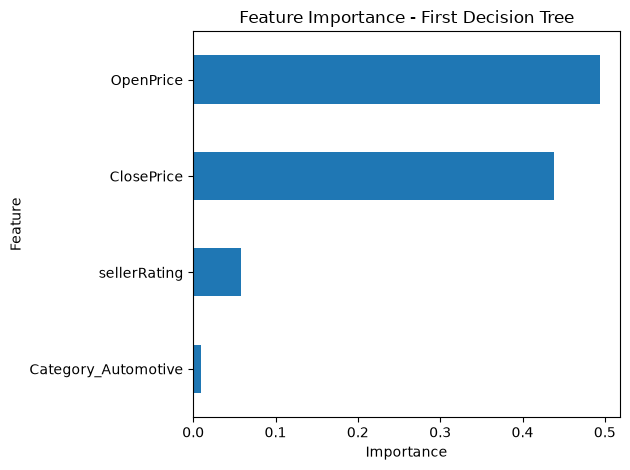

In [34]:
importance_all[importance_all["Importance"] > 0].plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title("Feature Importance - First Decision Tree")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 2.5 Predictor Reduction

In [35]:
unused_features = importance_all[importance_all["Importance"] == 0]

print("Number of unused predictors:", len(unused_features))
print(unused_features["Feature"].tolist())

Number of unused predictors: 32
['endDay_Tue', 'endDay_Thu', 'endDay_Sun', 'endDay_Sat', 'endDay_Mon', 'Category_Toys/Hobbies', 'Duration_10.0', 'Duration_7.0', 'Duration_5.0', 'Duration_3.0', 'Duration_1.0', 'Currency_US', 'Currency_GBP', 'Currency_EUR', 'endDay_Fri', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Photography', 'Category_Music/Movie/Game', 'Category_Jewelry', 'Category_Home/Garden', 'Category_Health/Beauty', 'Category_EverythingElse', 'Category_Electronics', 'Category_Computer', 'Category_Collectibles', 'Category_Coins/Stamps', 'Category_Clothing/Accessories', 'Category_Business/Industrial', 'Category_Books', 'Category_Antique/Art/Craft', 'endDay_Wed']


# Part 3: Classification Tree Using Practical Predictors

## 3.1 Model Training

For the purpose of prediction, closing price should be removed as it is not available at the time of a new auction.

In [36]:
# X_train_practical = X_train_practical.drop(unused_features["Feature"].tolist(), axis=1)
# X_test_practical = X_test_practical.drop(unused_features["Feature"].tolist(), axis=1)

In [37]:
tree_practical = DecisionTreeClassifier(
    criterion="gini",
    min_samples_leaf=50,
    random_state=5
)

tree_practical.fit(X_train_practical, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",5
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [38]:
print("Tree depth:", tree_practical.get_depth())
print("Number of terminal nodes:", tree_practical.get_n_leaves())
print("Training accuracy:", tree_practical.score(X_train_practical, y_train))
print("Test accuracy:", tree_practical.score(X_test_practical, y_test))

Tree depth: 7
Number of terminal nodes: 17
Training accuracy: 0.7413355874894336
Test accuracy: 0.6818757921419518


## 3.2 Plot and Decision Rules

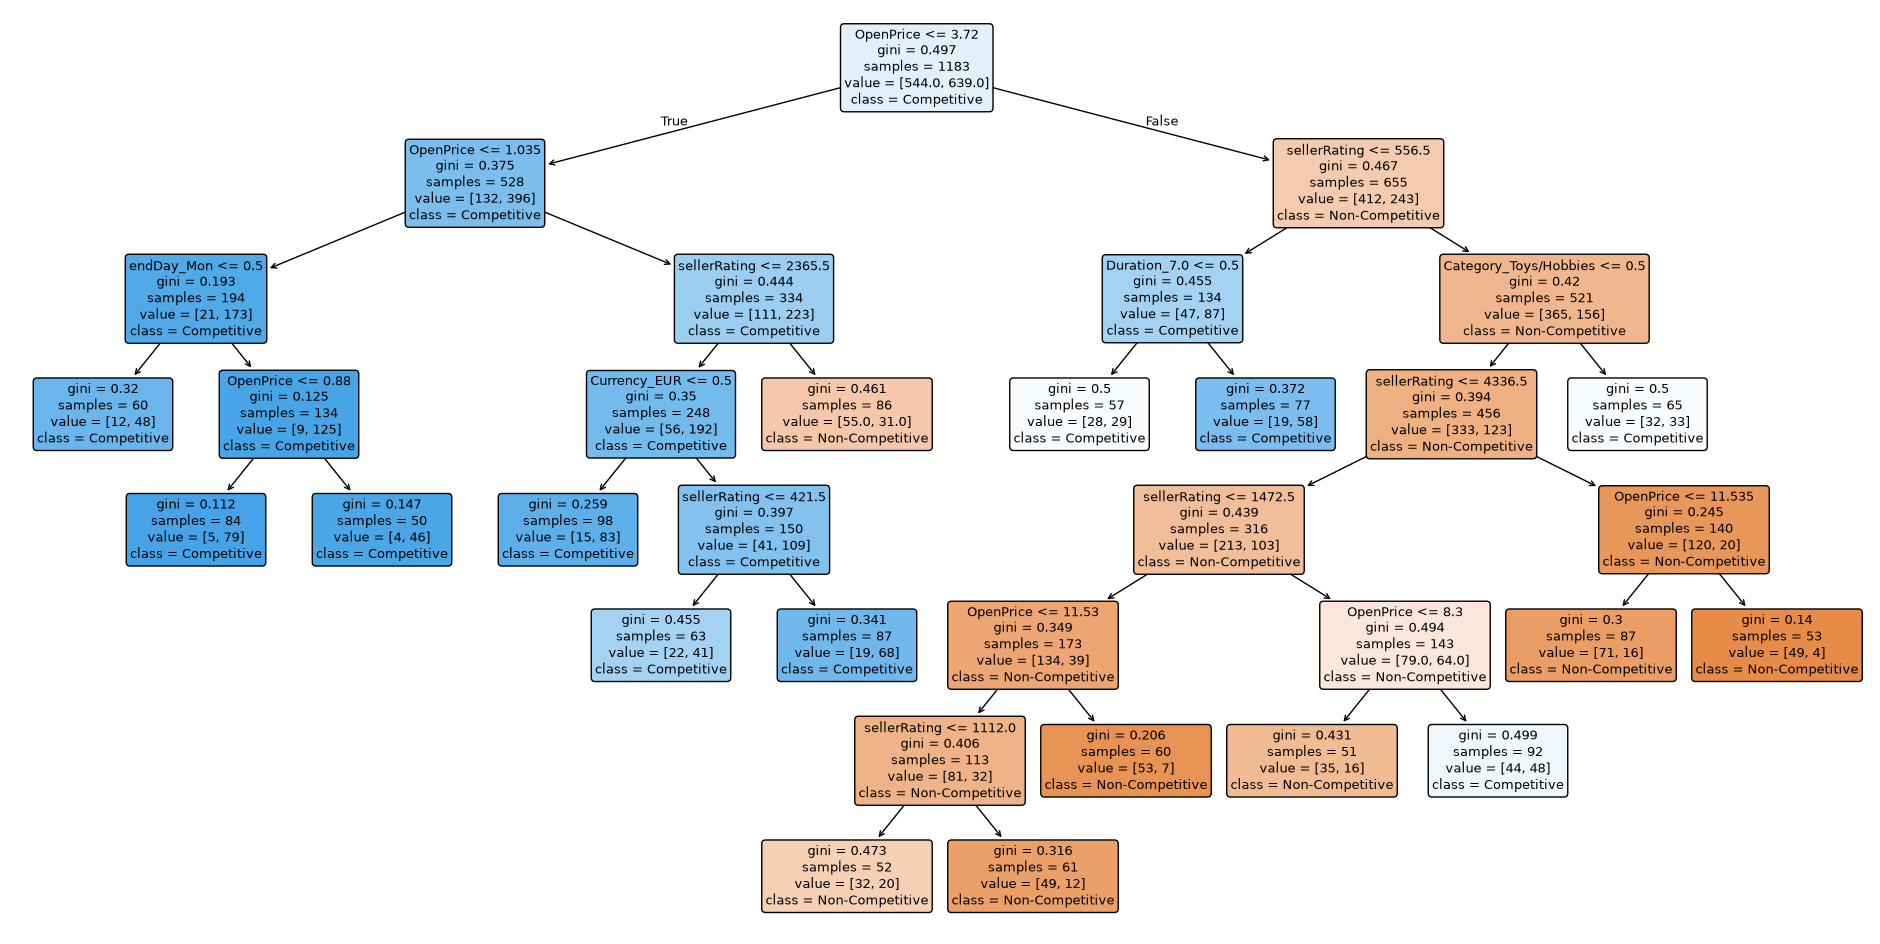

In [39]:
plt.figure(figsize=(24, 12))

plot_tree(
    tree_practical,
    feature_names=X_train_practical.columns,
    class_names=["Non-Competitive", "Competitive"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

In [40]:
rule_practical = export_text(
    tree_practical,
    feature_names=X_train_practical.columns)

print(rule_practical)

|--- OpenPrice <= 3.72
|   |--- OpenPrice <= 1.04
|   |   |--- endDay_Mon <= 0.50
|   |   |   |--- class: 1
|   |   |--- endDay_Mon >  0.50
|   |   |   |--- OpenPrice <= 0.88
|   |   |   |   |--- class: 1
|   |   |   |--- OpenPrice >  0.88
|   |   |   |   |--- class: 1
|   |--- OpenPrice >  1.04
|   |   |--- sellerRating <= 2365.50
|   |   |   |--- Currency_EUR <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Currency_EUR >  0.50
|   |   |   |   |--- sellerRating <= 421.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- sellerRating >  421.50
|   |   |   |   |   |--- class: 1
|   |   |--- sellerRating >  2365.50
|   |   |   |--- class: 0
|--- OpenPrice >  3.72
|   |--- sellerRating <= 556.50
|   |   |--- Duration_7.0 <= 0.50
|   |   |   |--- class: 1
|   |   |--- Duration_7.0 >  0.50
|   |   |   |--- class: 1
|   |--- sellerRating >  556.50
|   |   |--- Category_Toys/Hobbies <= 0.50
|   |   |   |--- sellerRating <= 4336.50
|   |   |   |   |--- sellerRating <= 1472.50
|   |

## 3.3 Feature Importance

In [41]:
importance_practical = pd.DataFrame({
    "Feature": X_train_practical.columns,
    "Importance": tree_practical.feature_importances_
}).sort_values("Importance", ascending=False)

importance_practical

,Feature,Importance
1,OpenPrice,0.564007
0,sellerRating,0.361242
19,Category_Toys/Hobbies,0.035580
26,Duration_7.0,0.021623
20,Currency_EUR,0.009470
29,endDay_Mon,0.008077
33,endDay_Tue,0.000000
32,endDay_Thu,0.000000
31,endDay_Sun,0.000000
30,endDay_Sat,0.000000


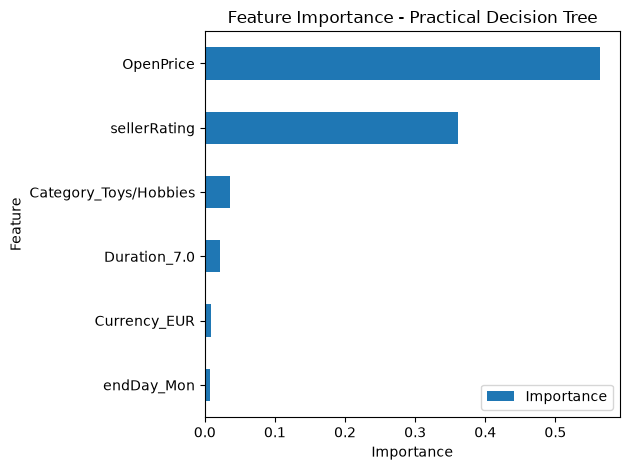

In [42]:
importance_practical[importance_practical["Importance"] > 0].plot(
    x="Feature",
    y="Importance",
    kind="barh"
)

plt.title("Feature Importance - Practical Decision Tree")
plt.xlabel("Importance")
plt.legend(loc="lower right")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()